![The blog’s ninja owl studying learning curves](https://howtolearnmachinelearning.com/wp-content/uploads/2026/11/learning-curves-anime-owl.png)

# Learning curves in Python
**Hey friends!** You can afford another round of data collection. Before you spend the budget, can you show that collecting more examples would help?

Your brief is to find the **smallest training size** that achieves mean validation squared error at or below **1.05** on this synthetic problem. You can choose a linear or cubic model. If both meet the target at the same size, choose the linear model for simplicity.

Run the cells in order. Pause at **Your attempt** to enter your choices and record your evidence. You can retry as often as you like. A CPU is enough and the data is generated here. [Read the companion article](https://howtolearnmachinelearning.com/articles/learning-curves-python/)

## 1. Inspect the development data
We have one numeric input and a continuous target. Look at the scatterplot. Where would a straight line give systematically poor predictions? Write down your guess before moving on.

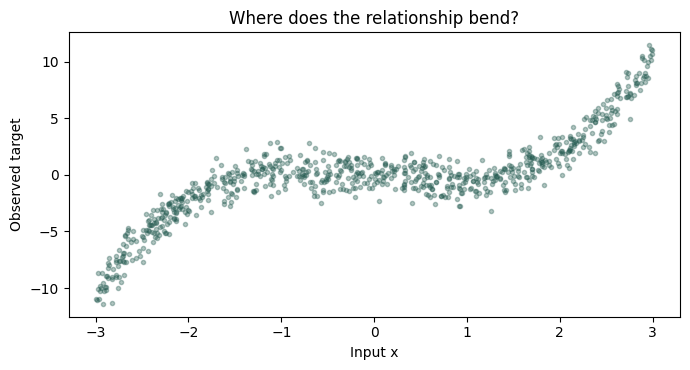

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge

rng = np.random.default_rng(42)
X = rng.uniform(-3, 3, size=(1000, 1))
y = 0.5 * X[:, 0]**3 - X[:, 0] + rng.normal(0, 1, size=1000)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

plt.figure(figsize=(7, 3.8))
plt.scatter(X_dev[:, 0], y_dev, s=9, alpha=0.35, color="#22594f")
plt.xlabel("Input x")
plt.ylabel("Observed target")
plt.title("Where does the relationship bend?")
plt.tight_layout()
plt.show()

## 2. Make the comparison fair
Each model sees the same five folds of the 800 development rows. In each fold, 160 rows supply validation scores and up to 640 supply training examples. Increasing the training size draws a larger subset within each fold. We keep 200 final test rows in reserve.

Both models use ridge regression and the same penalty. The cubic model can also use squared and cubed values of the input. Each pipeline learns its scaling from its own training subset.

In [2]:
models = {
    "Linear": make_pipeline(StandardScaler(), Ridge(alpha=0.1)),
    "Cubic": make_pipeline(PolynomialFeatures(degree=3, include_bias=False),
                           StandardScaler(), Ridge(alpha=0.1))
}
folds = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}
for name, model in models.items():
    sizes, training, validation = learning_curve(
        model, X_dev, y_dev, cv=folds, train_sizes=[0.025, 0.05, 0.1, 0.2, 0.5, 1.0],
        scoring="neg_mean_squared_error", shuffle=True, random_state=42,
        error_score="raise")
    # Convert scikit-learn's negative scores to ordinary MSE.
    results[name] = (-training, -validation)
print("Available training rows per fold:", list(map(int, sizes)))

Available training rows per fold: [16, 32, 64, 128, 320, 640]


## 3. Predict before you plot
Choose a model and estimate whether its validation error will **rise** or **fall** between 16 and 640 training rows. Give a reason, then run the cell. Compare the two endpoints with your prediction. Does the training error move in the same direction?

In [3]:
model_guess = None       # "Linear" or "Cubic"
direction_guess = None   # "rise" or "fall"
reason = ""              # What do you think extra examples will change?

if model_guess in models and direction_guess in ("rise", "fall") and reason.strip():
    training, validation = results[model_guess]
    first, last = validation.mean(axis=1)[[0, -1]]
    actual = "rise" if last > first else "fall" if last < first else "stay level"
    print(f"You expected a {direction_guess}. Observed: {first:.3f} → {last:.3f} ({actual}).")
    print(f"Training MSE: {training[0].mean():.3f} → {training[-1].mean():.3f}")
else:
    print("Enter a model, your prediction, and one reason. Then rerun this cell.")

Enter a model, your prediction, and one reason. Then rerun this cell.


## 4. Read both learning curves
Compare the *height* of each curve as well as the gap between training and validation. The shaded bands show one standard deviation across folds. A narrow gap at high error can mean both datasets are equally hard for the model to fit.

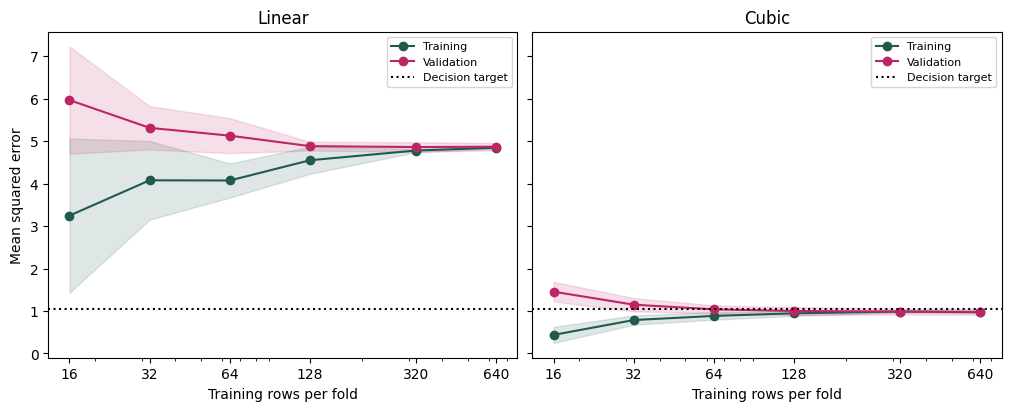

In [4]:
target_mse = 1.05
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
for ax, (name, pair) in zip(axes, results.items()):
    for values, label, color in zip(pair, ["Training", "Validation"], ["#22594f", "#bf2465"]):
        mean, spread = values.mean(axis=1), values.std(axis=1)
        ax.plot(sizes, mean, "o-", color=color, label=label)
        ax.fill_between(sizes, np.maximum(0, mean-spread), mean+spread, color=color, alpha=0.14)
    ax.axhline(target_mse, linestyle=":", color="black", label="Decision target")
    ax.set(title=name, xlabel="Training rows per fold", xscale="log")
    ax.set_xticks(sizes, labels=[str(n) for n in sizes])
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean squared error")
plt.show()

## 5. Your attempt · Meet the target with the fewest rows
Pick a model and a training size from the chart. Estimate its validation MSE. The checker will tell you the measured error and whether a smaller configuration qualifies. Use the feedback to revise one choice at a time.

**Decision note.** Edit this line after each trial: “I tried ___ with ___ rows. I expected ___ because ___. I observed ___, so my next choice is ___.”

In [5]:
def check_choice(model_name, rows, estimate):
    if model_name not in models or rows not in sizes:
        print("Choose Linear or Cubic and one of the six available training sizes.")
        return False
    if not isinstance(estimate, (int, float)) or not np.isfinite(estimate) or estimate < 0:
        print("Enter your estimate of validation MSE before revealing the result.")
        return False
    index = list(sizes).index(rows)
    measured = results[model_name][1][index].mean()
    print(f"Your estimate: {estimate:.3f}. Measured validation MSE: {measured:.3f}.")
    if measured > target_mse:
        print("Above target. Inspect the curve: would adding rows or changing the model help?")
        return False
    for size_index, size in enumerate(sizes):
        for candidate in ("Linear", "Cubic"):
            if results[candidate][1][size_index].mean() <= target_mse:
                if size == rows and candidate == model_name:
                    print("Target and budget checks passed. Which smaller option did you rule out?")
                    return True
                print("This meets the error target. Revisit the smallest qualifying size and tie rule.")
                return False
    return False

In [6]:
chosen_model = None      # "Linear" or "Cubic"
training_rows = None     # 16, 32, 64, 128, 320, or 640
estimated_mse = None     # Read an approximate value from the chart
solved = check_choice(chosen_model, training_rows, estimated_mse)

Choose Linear or Cubic and one of the six available training sizes.


## 6. Defend the decision
If your team offered to double the linear model’s training data, what evidence would you ask for before spending the money? Cite two observed errors and say where extrapolation begins. Then consider a new condition: if every fold had to meet the target, what would you check besides the mean?

[Companion article](https://howtolearnmachinelearning.com/articles/learning-curves-python/) · [Model evaluation guide](https://howtolearnmachinelearning.com/articles/evaluating-machine-learning-models/) · [Free 90-Day Machine Learning Roadmap](https://how-to-learn-machine-learning.kit.com/7a25f667cb)

## Worked answers
Open this section after recording your choice. Run the cell to compare every candidate and see what changes if the team cares about the worst fold.

In [7]:
print("Rows  Model    Mean validation MSE   Worst fold")
for index, size in enumerate(sizes):
    for name in ("Linear", "Cubic"):
        losses = results[name][1][index]
        print(f"{size:>4}  {name:<7}  {losses.mean():>13.3f}  {losses.max():>12.3f}")

Rows  Model    Mean validation MSE   Worst fold
  16  Linear           5.968         8.183
  16  Cubic            1.454         1.691
  32  Linear           5.314         6.270
  32  Cubic            1.148         1.403
  64  Linear           5.130         5.903
  64  Cubic            1.038         1.158
 128  Linear           4.883         5.004
 128  Cubic            1.000         1.134
 320  Linear           4.862         5.028
 320  Cubic            0.987         1.083
 640  Linear           4.870         4.992
 640  Cubic            0.982         1.086


**Choose the cubic model with 64 training rows per fold.** Its mean validation MSE is 1.038, below the 1.05 target. At the preceding tested size (32 rows), it scored 1.148. The table shows that every smaller candidate missed the target. This is a minimum among the six measured sizes. Intermediate sizes would require another experiment.

**Prediction check.** Across the endpoints, cubic validation MSE falls from 1.454 to 0.982 while training MSE rises from 0.437 to 0.970. A tiny sample is easy to fit closely. More examples help the model estimate the curve it will see on fresh cases.

**Budget decision.** The linear model’s mean validation MSE is 4.862 at 320 rows and 4.870 at 640. The gap between training and validation is small at 640, yet both errors are well above target. The cubic fit meets the target within the observed range. Predicting what happens at 1,280 rows would require evidence beyond this experiment.

**Changing the rule.** Inspect the worst-fold column if every fold must qualify. Fold-to-fold spread describes variation on these splits. A final performance estimate for a chosen configuration requires independent test data.